<a href="https://colab.research.google.com/github/Mahesh-Wali/AEC-LAB/blob/main/LAB_5_Program.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [1]:
import numpy as np
import matplotlib.pyplot as plt
from scipy import stats
import statsmodels.api as sm

In [2]:
# Data: Study Hours vs Exam Marks
x = np.array([2,3,5,6,7,8,9,10,11,12])
y = np.array([45,50,60,65,70,75,78,82,88,92])

In [3]:
# --- PEARSON CORRELATION (Manual) ---
x_bar, y_bar = np.mean(x), np.mean(y)
num   = np.sum((x-x_bar)*(y-y_bar))
den_x = np.sqrt(np.sum((x-x_bar)**2))
den_y = np.sqrt(np.sum((y-y_bar)**2))
r = num / (den_x * den_y)
print(f'Pearson r (manual) = {r:.6f}')

r_scipy, p_val = stats.pearsonr(x, y)
print(f'Pearson r (scipy)  = {r_scipy:.6f}, p={p_val:.6f}')

Pearson r (manual) = 0.998829
Pearson r (scipy)  = 0.998829, p=0.000000


In [4]:
# --- REGRESSION COEFFICIENTS ---
byx = r * (den_y / den_x)   # Regression Y on X
bxy = r * (den_x / den_y)   # Regression X on Y
print(f'byx = {byx:.4f}  (Y on X slope)')
print(f'bxy = {bxy:.4f}  (X on Y slope)')
print(f'r²  = byx × bxy = {byx*bxy:.4f}  (should = {r**2:.4f})')

byx = 4.6703  (Y on X slope)
bxy = 0.2136  (X on Y slope)
r²  = byx × bxy = 0.9977  (should = 0.9977)


In [5]:
# Regression equations
c_yx = y_bar - byx * x_bar
c_xy = x_bar - bxy * y_bar
print(f'Line Y on X: y = {byx:.4f}x + {c_yx:.4f}')
print(f'Line X on Y: x = {bxy:.4f}y + {c_xy:.4f}')

Line Y on X: y = 4.6703x + 36.4066
Line X on Y: x = 0.2136y + -7.7600


In [6]:
# Prediction
x_pred = 7.5
y_pred = byx * x_pred + c_yx
print(f'Predicted marks for {x_pred} hours = {y_pred:.2f}')

Predicted marks for 7.5 hours = 71.43


In [7]:
# --- SPEARMAN RANK CORRELATION ---
judge_A = np.array([1,2,3,4,5,6,7,8,9,10])
judge_B = np.array([3,4,2,1,5,8,7,6,9,10])
d = judge_A - judge_B
n_r = len(judge_A)
rho = 1 - 6*np.sum(d**2) / (n_r*(n_r**2-1))
print(f'Spearman ρ (manual) = {rho:.6f}')

rho_s, _ = stats.spearmanr(judge_A, judge_B)
print(f'Spearman ρ (scipy)  = {rho_s:.6f}')

Spearman ρ (manual) = 0.842424
Spearman ρ (scipy)  = 0.842424


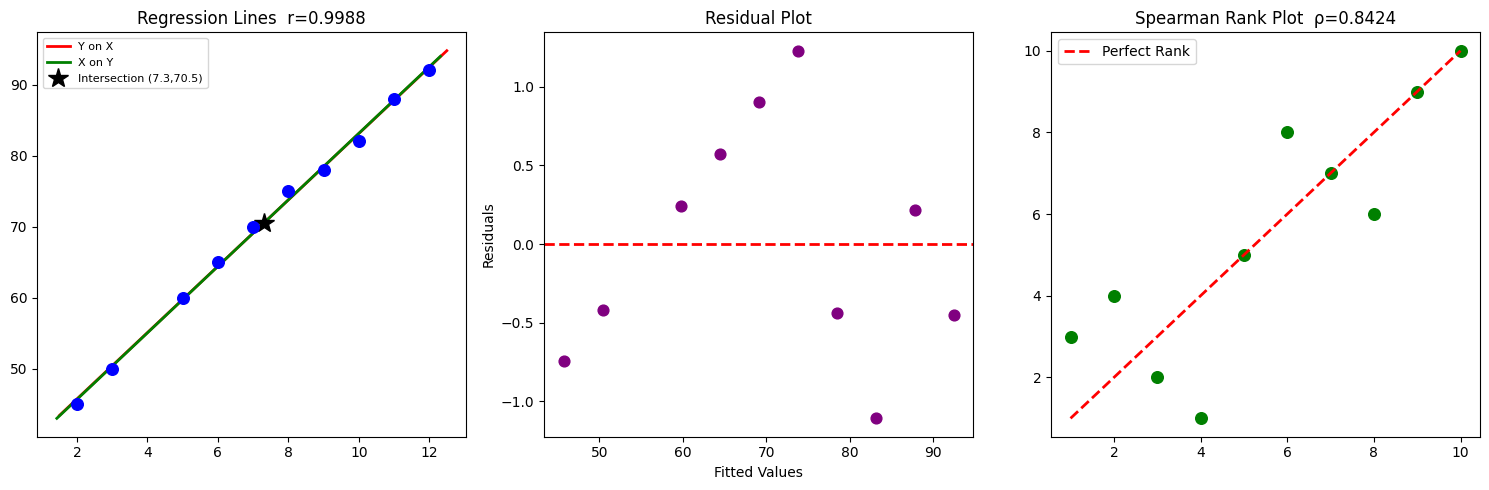

In [8]:
# --- VISUALIZATION ---
fig, axes = plt.subplots(1, 3, figsize=(15, 5))

# Both regression lines
xf = np.linspace(x.min()-0.5, x.max()+0.5, 200)
yf = np.linspace(y.min()-2, y.max()+2, 200)

axes[0].scatter(x, y, color='blue', s=70, zorder=5)
axes[0].plot(xf, byx*xf+c_yx, 'r-', lw=2, label='Y on X')
axes[0].plot(bxy*yf+c_xy, yf, 'g-', lw=2, label='X on Y')
axes[0].plot(x_bar, y_bar, 'k*', ms=15, label=f'Intersection ({x_bar:.1f},{y_bar:.1f})')
axes[0].set_title(f'Regression Lines  r={r:.4f}')
axes[0].legend(fontsize=8)

# Residual plot
y_fit  = byx*x + c_yx
resid  = y - y_fit
axes[1].scatter(y_fit, resid, color='purple', s=60)
axes[1].axhline(0, color='red', linestyle='--', lw=2)
axes[1].set_xlabel('Fitted Values')
axes[1].set_ylabel('Residuals')
axes[1].set_title('Residual Plot')

# Rank correlation
axes[2].scatter(judge_A, judge_B, color='green', s=70)
axes[2].plot([1,10],[1,10],'r--',lw=2,label='Perfect Rank')
axes[2].set_title(f'Spearman Rank Plot  ρ={rho:.4f}')
axes[2].legend()

plt.tight_layout(); plt.show()